# 06 - Lime recurrence intervals

Liming recommendations are for a single-dose, which makes them hard to compare to mean annual fluxes predicted by ERW models. We try to derive a conservative long-term flux estimate for liming by using the upper-bound of estimated recurrence intervals across the US. The upper-bound is appropriate because these data reflect actual lime application, which is thought to fall below lime recommendations ([Woollen et al. (preprint)](https://cdrxiv.org/preprint/535)) (i.e., the represented liming frequency may not be what an ag extension would recommend).

We pull lime frequency data for 1954–1987 (Tsao et al., [Zenodo 15758275](https://doi.org/10.5281/zenodo.15758275)). Here, frequency is defined as the limed area divided by the cropland area (yr-1), and the recurrence interval is 1/frequency if we assume uniform application and a regular rotation. 

Counties are weighted by cropland area; counties with no liming in a census year (frequency 0) are excluded.

24,936 county-years; 28% of cropland in counties with no liming that year


/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_13386/3934315211.py:12: RuntimeWarning: divide by zero encountered in divide
  top = ax.secondary_xaxis("top", functions=(lambda x: 1 / x, lambda x: 1 / x)); top.set_xlabel("recurrence interval, yr");


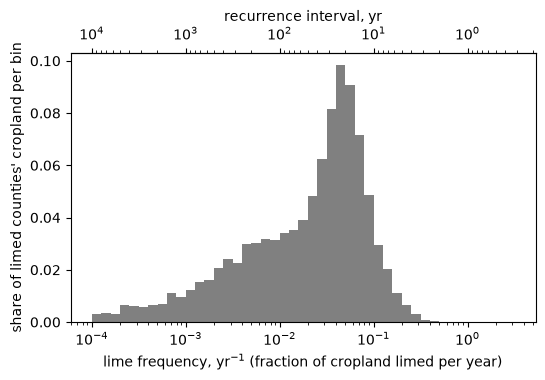

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

T = pd.read_csv("../data/external/tsao2025/county_lime_1954_1987.csv")
f, w = T.LimeFreq.to_numpy(), T.CropArea.to_numpy()
print(f"{len(T):,} county-years; {w[f == 0].sum() / w.sum():.0%} of cropland in counties with no liming that year")

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.logspace(-4, 0.5, 46)
ax.hist(f[f > 0], bins=bins, weights=w[f > 0] / w[f > 0].sum(), color="0.5")
ax.set_xscale("log"); ax.set_xlabel("lime frequency, yr$^{-1}$ (fraction of cropland limed per year)")
ax.set_ylabel("share of limed counties' cropland per bin")
top = ax.secondary_xaxis("top", functions=(lambda x: 1 / x, lambda x: 1 / x)); top.set_xlabel("recurrence interval, yr");

In [5]:
PERCENTILE = 99      # cropland-weighted, counties with any liming that year (frequency > 0)

m = f > 0
o = np.argsort(f[m]); fs, ws = f[m][o], w[m][o]
fq = np.interp(PERCENTILE / 100, (np.cumsum(ws) - 0.5 * ws) / ws.sum(), fs)
print(f"P{PERCENTILE} frequency: {fq:.4f} yr-1  ->  recurrence interval: {1 / fq:.0f} yr")

P99 frequency: 0.2041 yr-1  ->  recurrence interval: 5 yr


In [ ]:
# ---